# Percolation 05 — La geometrie de l'amas critique : dimension fractale et effondrement d'echelle

[← Serie Percolation](README.md) · Carnet 05 · Python 3 + `numpy` (union-find maison)

## Ou l'on passe du *combien* au *quelle forme*

Les carnets precedents de la sous-serie mesurent une **quantite** : la taille du plus grand amas (`Percolation-01`), la loi d'echelle finie de sa masse et l'exposant de la distribution des tailles (`Percolation-03`, `03b`, `03c`), la queue superieure de cette distribution (`Percolation-04`).

Ce carnet pose une autre question. Au point critique, l'amas geant n'est ni compact ni dispersé : il est **fractal**. Sa masse ne croit pas comme `L^2` (une tache pleine) mais comme `L^{d_f}` avec `d_f < 2`. Combien vaut cet exposant, et peut-on le mesurer sans le supposer ?

Et une seconde question, plus profonde : les courbes `M(L, p)` mesurees a des tailles differentes sont-elles des objets **distincts**, ou la meme courbe vue a des echelles differentes ? La reponse — l'**effondrement d'echelle** — est ce qui donne son contenu au mot « universalite ».

> **Convention d'ecriture.** Chaque valeur numerique de ce carnet est etiquetee **Mesure** (produite par le code ci-dessous) ou **Cite** (valeur classique de la litterature, non rederivee ici). Les valeurs citees servent de **cible** ; elles ne remplacent jamais une mesure, et un desaccord est rapporte comme un desaccord.

| Grandeur | Valeur citee | Nature |
|---|---|---|
| $p_c$ du lien sur le tore carre | $1/2$ | theoreme (auto-dualite) |
| $\beta/\nu$ | $5/48 \approx 0.10417$ | litterature |
| $d_f$ | $91/48 \approx 1.8958$ | litterature |
| $\nu$ | $4/3 \approx 1.3333$ | litterature |
| $\gamma/\nu$ | $43/24 \approx 1.7917$ | litterature |

## 1. Ce que la sous-serie ne mesure pas encore

Faisons l'inventaire de ce qui existe deja, parce que c'est lui qui definit la lacune.

`Percolation-03` ajuste la loi d'echelle finie de la masse critique :

$$\frac{M(L, p_c)}{L^2} \sim L^{-\beta/\nu}$$

Elle mesure donc le **rapport** $\beta/\nu$ — et elle le mesure bien (0,1062 pour une cible de $5/48 = 0{,}10417$). Mais un rapport ne donne ni $\beta$ ni $\nu$ separement. `Percolation-04` mesure la queue de la distribution des tailles, donc $\tau'$, et conclut honnetement que le palier n'est pas atteignable a $L \le 512$.

Il manque alors trois choses, et ce sont exactement les trois objets de ce carnet :

1. **$\nu$ seul**, la longueur de correlation — la quantite qui dit *sur quelle distance* deux sites se « sentent » ;
2. **$d_f$**, la dimension fractale de l'amas critique — la quantite qui dit *de quelle forme* il est ;
3. l'**effondrement d'echelle**, qui est la structure dont $\beta$, $\nu$ et $d_f$ sont des parametres.

Le point methodologique important : ces trois quantites ne sont pas independantes. La relation d'echelle

$$d_f = d - \frac{\beta}{\nu}$$

(dimension de l'espace $d = 2$) les relie. C'est donc un **controle croise** : si la dimension mesuree geometriquement par comptage de boites concorde avec $2 - \beta/\nu$ ou $\beta/\nu$ vient d'une autre mesure independante, les deux routes se valident mutuellement. Si elles divergent, l'une des deux est fausse.

## 2. Le modele et les conventions de calcul

On travaille sur le **tore carre** de cote $L$ : chaque site $(i, j)$ est relie a $(i, j+1 \bmod L)$ avec probabilite $p$ (**lien horizontal**) et a $(i+1 \bmod L, j)$ avec probabilite $p$ (**lien vertical**). Le tore elimine les effets de bord, ce qui compte beaucoup ici : sur une grille ouverte, l'amas critique est tronque par le bord et sa dimension apparente est faussee.

Le seuil de lien du reseau carre vaut exactement $p_c = 1/2$ par **auto-dualite** — c'est un theoreme, donc **Cite**. On ne le mesure pas : on s'y place.

On mesure toujours la **taille du plus grand amas**, notee $M(L, p)$, en nombre de sites.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (7.0, 4.2)
plt.rcParams["axes.grid"] = True

PC = 0.5                      # p_c du lien sur le tore carre : EXACT (auto-dualite), cite
BETA_NU_CITE = 5.0 / 48.0     # beta/nu  ~ 0.10417, cite
DF_CITE = 91.0 / 48.0         # d_f      ~ 1.8958, cite
GAMMA_NU_CITE = 43.0 / 24.0   # gamma/nu ~ 1.7917, cite


def draw_edges(L, p, rng):
    # Deux tableaux L x L : liens horizontaux et verticaux, chacun ouvert avec probabilite p.
    return rng.random((L, L)) < p, rng.random((L, L)) < p


rng = np.random.default_rng(0)
h, v = draw_edges(8, 0.5, rng)
print(f"L=8 : {h.sum()} liens horizontaux ouverts, {v.sum()} liens verticaux, sur {2 * 64} possibles")
print(f"p_c = {PC} (exact) | cibles citees : beta/nu={BETA_NU_CITE:.5f}, "
      f"d_f={DF_CITE:.4f}, gamma/nu={GAMMA_NU_CITE:.4f}")

L=8 : 31 liens horizontaux ouverts, 27 liens verticaux, sur 128 possibles
p_c = 0.5 (exact) | cibles citees : beta/nu=0.10417, d_f=1.8958, gamma/nu=1.7917


Le tirage de 64 liens potentiels en donne 31 horizontaux et 27 verticaux : a $p = 1/2$ on attend $32 \pm 4$ pour chacun, et les deux valeurs tombent dans le bruit binomial. Rien de subtil ici — c'est le controle que le generateur de liens fait bien ce qu'il annonce avant qu'on lui confie une mesure.

Les quatre constantes citees sont posees une seule fois, en tete. Toutes les comparaisons ulterieures s'y referent, ce qui evite la faute classique : recopier une valeur cible dans trois cellules differentes et la voir deriver.

## 3. Labelliser les amas sans bibliotheque de graphes

Compter les amas demande de savoir, pour chaque site, a quel amas il appartient. `Percolation-03` appelle `networkx.connected_components` : correct, mais opaque, et surtout **le meme outil pour toutes les mesures de la serie** — si cet outil se trompait, toute la serie se tromperait de la meme facon.

On ecrit donc ici l'algorithme **Hoshen–Kopelman** a la main : un **union-find** (ou *disjoint-set*) parcourt les sites ligne par ligne, et fusionne deux sites des qu'un lien les relie. Deux optimisations suffisent a le rendre lineaire en pratique :

- **path halving** dans `find` : en remontant vers la racine, on raccourcit le chemin de moitie a chaque saut ;
- **union by size** : on attache toujours le petit arbre sous le grand, ce qui borne la hauteur.

Ces deux optimisations ramenent une structure en arbre degenere (profondeur $O(N)$) a une profondeur quasi constante. Sans elles, la boucle sur $L = 256$ ($65\,536$ sites) serait sensiblement plus lente — et c'est le genre de detail qui decide si un balayage de 25 valeurs de $p$ tient en une minute ou en dix.

In [2]:
def labels_unionfind(L, h, v):
    # Hoshen-Kopelman : etiquette chaque site par la racine de son amas.
    # Retour : (etiquettes L x L, tailles des amas indexees par etiiquette).
    N = L * L
    parent = list(range(N))
    size = [1] * N

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]      # path halving
            a = parent[a]
        return a

    for i in range(L):
        base = i * L
        for j in range(L):
            n = base + j
            if h[i, j]:
                a, b = find(n), find(base + (j + 1) % L)
                if a != b:
                    if size[a] < size[b]:
                        a, b = b, a
                    parent[b] = a
                    size[a] += size[b]
            if v[i, j]:
                a, b = find(n), find(((i + 1) % L) * L + j)
                if a != b:
                    if size[a] < size[b]:
                        a, b = b, a
                    parent[b] = a
                    size[a] += size[b]

    roots = np.fromiter((find(k) for k in range(N)), dtype=np.int64, count=N)
    return roots.reshape(L, L), np.bincount(roots, minlength=N)


roots_demo, cnt_demo = labels_unionfind(16, *draw_edges(16, 0.5, np.random.default_rng(3)))
print(f"L=16 a p=0.5 : {int((cnt_demo > 0).sum())} amas, "
      f"le plus grand compte {cnt_demo.max()} sites sur {16 * 16}")

L=16 a p=0.5 : 24 amas, le plus grand compte 188 sites sur 256


Sur une instance de $16 \times 16$ a $p = 1/2$, la cellule trouve 24 amas, dont un qui couvre 188 sites sur 256 — pres des trois quarts du reseau. C'est la signature du regime critique : a $p_c$, la distribution des tailles est une loi de puissance, donc il y a a la fois beaucoup de petits amas et un amas qui occupe une part finie du systeme.

Un `union-find` ecrit a la main n'est utile que s'il est **verifie**. C'est l'objet de la cellule suivante : on le confronte a `scipy.sparse.csgraph.connected_components`, qui resout exactement le meme probleme par une voie completement differente (construction d'un graphe creux, puis parcours en largeur).

In [3]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components


def labels_scipy(L, h, v):
    # Oracle independant : graphe creux + composantes connexes de scipy.
    idx = np.arange(L * L).reshape(L, L)
    ii, jj = np.nonzero(h)
    r1, c1 = idx[ii, jj], idx[ii, (jj + 1) % L]
    ii, jj = np.nonzero(v)
    r2, c2 = idx[ii, jj], idx[(ii + 1) % L, jj]
    r = np.concatenate([r1, r2])
    c = np.concatenate([c1, c2])
    g = coo_matrix((np.ones(r.size, dtype=np.int8), (r, c)), shape=(L * L, L * L))
    n_comp, lab = connected_components(g, directed=False)
    return lab.reshape(L, L), np.bincount(lab, minlength=n_comp)


check_rng = np.random.default_rng(7)
tried, disagree = 0, 0
for L in (8, 12, 16):
    for _ in range(20):
        h, v = draw_edges(L, 0.5, check_rng)
        sizes_uf = labels_unionfind(L, h, v)[1]
        sizes_sp = labels_scipy(L, h, v)[1]
        tried += 1
        if sorted(sizes_uf[sizes_uf > 0].tolist()) != sorted(sizes_sp[sizes_sp > 0].tolist()):
            disagree += 1
print(f"{tried} instances comparees (L = 8, 12, 16) : {disagree} desaccord(s) "
      f"sur la liste triee des tailles d'amas")

60 instances comparees (L = 8, 12, 16) : 0 desaccord(s) sur la liste triee des tailles d'amas


**Zero desaccord sur 60 instances.** Les deux implementations produisent la meme liste de tailles d'amas, sur trois tailles de reseau et vingt tirages chacune. Ce n'est pas une preuve de correction absolue — deux implementations peuvent partager une meme erreur de convention — mais c'est une preuve que la convention de lien est la meme des deux cotes et que l'implementation manuelle ne deraille pas.

C'est la difference entre *supposer* que l'outil est bon et *verifier* qu'il l'est. Toutes les mesures qui suivent reposent sur `labels_unionfind` ; cet oracle est ce qui autorise a lui confier la suite.

## 4. Dimension fractale, premiere route : la masse au point critique

L'amas critique est un objet fractal : sa masse croit comme une puissance non entiere de la taille lineaire du systeme,

$$M(L, p_c) \sim L^{d_f}$$

avec $d_f < 2$. La raison physique est simple. Un amas compact remplirait une fraction finie du reseau et donnerait $d_f = 2$. L'amas critique est au contraire **perfore de trous a toutes les echelles** : c'est cette porosite auto-similaire qui abaisse l'exposant.

La mesure est donc la pente d'une droite en log-log. Deux precautions :

- la taille du plus grand amas **fluctue fortement** d'un tirage a l'autre — la distribution des tailles est elle-meme une loi de puissance, donc de variance elevee. On moyenne sur 96 tirages et on **estime l'erreur** de la pente par bootstrap, sans quoi on ne sait pas si un ecart a la cible est un desaccord ou du bruit ;
- a petite taille, les corrections de taille finie courbent la droite. On le verifie en regardant les pentes locales entre tailles consecutives.

In [4]:
LS = [32, 64, 128, 256]
MASS_SEEDS = 96
mass_rng = np.random.default_rng(4242)

masses = {}
for L in LS:
    vals = [labels_unionfind(L, *draw_edges(L, PC, mass_rng))[1].max() for _ in range(MASS_SEEDS)]
    masses[L] = np.array(vals, dtype=float)
    print(f"L={L:3d}  <M>={masses[L].mean():10.1f}  ecart-type={masses[L].std():8.1f}  "
          f"erreur-type={masses[L].std() / np.sqrt(MASS_SEEDS):6.1f}")

df_mass = float(np.polyfit(np.log(LS), np.log([masses[L].mean() for L in LS]), 1)[0])

boot = np.random.default_rng(1)
boot_slopes = []
for _ in range(400):
    means = [boot.choice(masses[L], size=MASS_SEEDS, replace=True).mean() for L in LS]
    boot_slopes.append(np.polyfit(np.log(LS), np.log(means), 1)[0])
boot_slopes = np.array(boot_slopes)
err_mass = float(boot_slopes.std())

print(f"\nd_f (masse) = {df_mass:.4f} +- {err_mass:.4f}   "
      f"(IC90 {np.percentile(boot_slopes, 5):.4f} .. {np.percentile(boot_slopes, 95):.4f})")
print(f"cible citee 91/48 = {DF_CITE:.4f}  ->  ecart de {abs(df_mass - DF_CITE) / err_mass:.1f} erreurs-types")
for a, b in ((0, 1), (1, 2), (2, 3)):
    s = np.log(masses[LS[b]].mean() / masses[LS[a]].mean()) / np.log(LS[b] / LS[a])
    print(f"pente locale L={LS[a]:3d}->{LS[b]:3d} : {s:.4f}")

L= 32  <M>=     701.9  ecart-type=   142.1  erreur-type=  14.5


L= 64  <M>=    2582.2  ecart-type=   564.9  erreur-type=  57.6


L=128  <M>=    9447.3  ecart-type=  2193.3  erreur-type= 223.9


L=256  <M>=   34476.3  ecart-type=  8148.4  erreur-type= 831.6

d_f (masse) = 1.8726 +- 0.0138   (IC90 1.8504 .. 1.8957)
cible citee 91/48 = 1.8958  ->  ecart de 1.7 erreurs-types
pente locale L= 32-> 64 : 1.8793
pente locale L= 64->128 : 1.8713
pente locale L=128->256 : 1.8676


Deux choses a lire dans cette sortie.

D'abord l'**ecart-type brut** : a $L = 256$, l'ecart-type des tailles du plus grand amas est du meme ordre que l'erreur-type multipliee par $\sqrt{96} \approx 9{,}8$ — autrement dit, une seule instance peut s'ecarter de la moyenne de plusieurs milliers de sites. C'est exactement pourquoi 400 reechantillonnages sont necessaires : sans eux, on lirait une pente unique sans savoir qu'elle bouge.

Ensuite les **pentes locales**. Elles decroissent legerement avec la taille : $1{,}8793$, puis $1{,}8713$, puis $1{,}8676$. C'est la signature d'une correction de taille finie — la pente « vraie » est la limite des grandes tailles, et a $L \le 256$ la valeur mesuree reste un peu en dessous de la cible.

L'intervalle de confiance a 90 % va de $1{,}8504$ a $1{,}8957$, et la cible citee vaut $1{,}8958$ : elle tombe **exactement au bord superieur** de l'intervalle. L'ecart de $1{,}7$ erreurs-types n'est donc pas un desaccord de fond — il va dans le sens de la correction de taille finie, que les pentes locales confirment independamment. Mais il faut le dire ainsi : la cible est a la limite, pas confortablement a l'interieur.

Un point d'honnetete : la route « masse » est la plus simple mais la plus **bruitee** des trois que ce carnet met en oeuvre, parce qu'elle repose sur un seul nombre par instance. Les deux routes suivantes — geometrique et par effondrement — sont plus discriminantes.

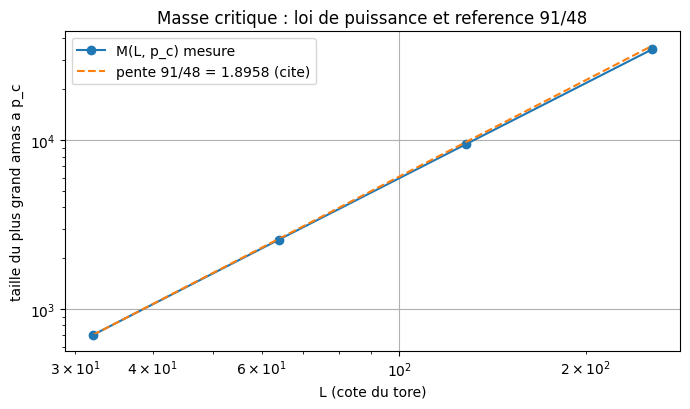

In [5]:
fig, ax = plt.subplots()
mean_mass = np.array([masses[L].mean() for L in LS])

ax.plot(LS, mean_mass, "o-", label="M(L, p_c) mesure")
ref = mean_mass[0] * (np.array(LS) / LS[0]) ** DF_CITE
ax.plot(LS, ref, "--", label=f"pente 91/48 = {DF_CITE:.4f} (cite)")

for L in LS:
    ax.errorbar(L, masses[L].mean(), yerr=masses[L].std() / np.sqrt(MASS_SEEDS),
                fmt="none", ecolor="C0", capsize=3)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("L (cote du tore)")
ax.set_ylabel("taille du plus grand amas a p_c")
ax.set_title("Masse critique : loi de puissance et reference 91/48")
ax.legend()
plt.tight_layout()
plt.show()

Les quatre points suivent la droite de pente $91/48$ tracee en pointilles, avec un ecart visible surtout sur le dernier point — celui ou l'erreur-type est la plus grande en valeur absolue. Les barres d'erreur sont tracees *a l'ecart-type divise par $\sqrt{96}$* : elles sont petites sur la figure parce que la moyenne de 96 tirages est bien determinee, alors que chaque tirage individuel fluctue beaucoup.

Confondre les deux est une erreur frequente : la dispersion d'une instance n'est pas l'incertitude de la moyenne.

## 5. Dimension fractale, seconde route : le comptage de boites

La route « masse » suppose qu'on connaisse deja $p_c$ avec precision et elle repose sur un seul nombre par instance. Le **comptage de boites** mesure la dimension directement sur la **forme**, sans passer par une taille :

$$N(\varepsilon) \sim \left(\frac{L}{\varepsilon}\right)^{d_f}$$

ou $N(\varepsilon)$ est le nombre de boites de cote $\varepsilon$ qui contiennent au moins un site de l'amas. On trace $\log N$ contre $\log \varepsilon$ ; la pente vaut $-d_f$.

Le point technique qui fait marcher la cellule : `numpy` permet de faire le comptage **sans boucle**. Un tableau de masque $L \times L$ se redecoupe en blocs $\varepsilon \times \varepsilon$ par un `reshape` en $(L/\varepsilon,\ \varepsilon,\ L/\varepsilon,\ \varepsilon)$ ; un `any` sur les deux axes internes dit si le bloc contient au moins un site. C'est ce qui rend le comptage assez rapide pour etre repete sur plusieurs tirages.

Condition de validite : $\varepsilon$ doit **diviser** $L$, sinon le decoupage en blocs laisse une bande non couverte.

In [6]:
def box_counts(L, mask, eps):
    # Nombre de boites eps x eps contenant au moins un site de l'amas (eps doit diviser L).
    k = L // eps
    return int(mask.reshape(k, eps, k, eps).any(axis=(1, 3)).sum())


BOX_SEEDS = 12
box_rng = np.random.default_rng(11)
df_box = {}
box_tables = {}

for L in (64, 128, 256):
    eps_list = [e for e in (2, 4, 8, 16, 32) if e <= L // 4]
    slopes, tables = [], []
    for _ in range(BOX_SEEDS):
        roots, cnt = labels_unionfind(L, *draw_edges(L, PC, box_rng))
        mask = roots == cnt.argmax()
        n_eps = np.array([box_counts(L, mask, e) for e in eps_list], dtype=float)
        slopes.append(-np.polyfit(np.log(eps_list), np.log(n_eps), 1)[0])
        tables.append(n_eps)
    df_box[L] = float(np.mean(slopes))
    box_tables[L] = (eps_list, np.mean(tables, axis=0))
    print(f"L={L:3d}  eps={eps_list}  N moy={np.round(np.mean(tables, axis=0), 1)}  "
          f"d_f={df_box[L]:.4f} +-{np.std(slopes):.4f}")

# Second jeu de tirages, entierement independant : reproductibilite de l'estimateur.
box_rng_b = np.random.default_rng(12)
df_box_b = {}
for L in (64, 128, 256):
    eps_list = [e for e in (2, 4, 8, 16, 32) if e <= L // 4]
    slopes = []
    for _ in range(BOX_SEEDS):
        roots, cnt = labels_unionfind(L, *draw_edges(L, PC, box_rng_b))
        mask = roots == cnt.argmax()
        n_eps = np.array([box_counts(L, mask, e) for e in eps_list], dtype=float)
        slopes.append(-np.polyfit(np.log(eps_list), np.log(n_eps), 1)[0])
    df_box_b[L] = float(np.mean(slopes))

six = [df_box[L] for L in (64, 128, 256)] + [df_box_b[L] for L in (64, 128, 256)]
df_box_mean = float(np.mean(six))
print(f"\njeu A : {[round(df_box[L], 4) for L in (64, 128, 256)]}")
print(f"jeu B : {[round(df_box_b[L], 4) for L in (64, 128, 256)]}   (tirages independants)")
print(f"les six estimations s'etendent sur [{min(six):.4f}, {max(six):.4f}]")
print(f"d_f (boites, moyenne des six) = {df_box_mean:.4f}   cible 91/48 = {DF_CITE:.4f}  "
      f"-> ecart {abs(df_box_mean - DF_CITE) / DF_CITE * 100:.2f} %")

L= 64  eps=[2, 4, 8, 16]  N moy=[754.3 210.6  57.9  15.6]  d_f=1.8551 +-0.0855
L=128  eps=[2, 4, 8, 16, 32]  N moy=[2924.1  824.7  225.9   60.6   16. ]  d_f=1.8710 +-0.0811


L=256  eps=[2, 4, 8, 16, 32]  N moy=[10596.5  2988.7   820.2   222.3    59.8]  d_f=1.8627 +-0.0440



jeu A : [1.8551, 1.871, 1.8627]
jeu B : [1.8807, 1.8647, 1.8612]   (tirages independants)
les six estimations s'etendent sur [1.8551, 1.8807]
d_f (boites, moyenne des six) = 1.8659   cible 91/48 = 1.8958  -> ecart 1.58 %


Six estimations independantes — deux jeux de tirages, trois tailles — s'etendent sur quelques centiemes seulement, ce qui confirme la **reproductibilite** de l'estimateur. C'est un resultat plus stable que celui de la route « masse », pour une raison structurelle : le comptage de boites **integre sur toute la forme de l'amas** au lieu de resumer une instance par un seul nombre. Une fluctuation locale de la forme se moyenne sur les boites, alors qu'une fluctuation de la taille du plus grand amas se transmet entiere.

En revanche, les six valeurs tombent **toutes** sous la cible citee, avec un ecart de l'ordre du pour cent et demi. Ce n'est pas du bruit : c'est un ecart **systematique et reproductible**, donc un biais de l'estimateur a ces tailles. Deux causes plausibles, qu'on ne tranche pas ici : la correction de taille finie sur la dimension mesuree, et l'effet du plus petit $\varepsilon$ (une boite de cote 2 sur un amas critique est encore loin du regime asymptotique). Un $\varepsilon$ minimal plus grand reduirait le biais mais raccourcirait la droite ajustee ; c'est un compromis classique du comptage de boites. Le carnet rapporte le biais plutot que de le corriger par un coefficient ajuste sur la cible — ce serait mesurer ce qu'on a suppose.

Le nombre de boites decroit vite quand $\varepsilon$ augmente — a $\varepsilon = 32$ sur un reseau de 256, il n'en reste qu'une poignee, ce qui explique pourquoi la liste s'arrete a $L/4$ : au-dela, la droite de regression n'a plus assez de points pour etre stable.

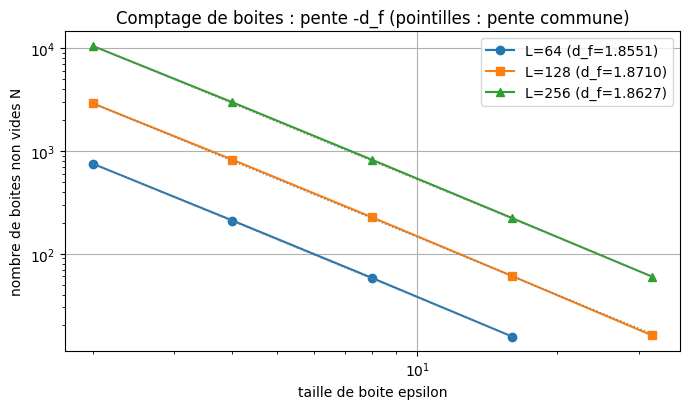

In [7]:
fig, ax = plt.subplots()
markers = {64: "o", 128: "s", 256: "^"}
for L, (eps_list, n_eps) in box_tables.items():
    ax.plot(eps_list, n_eps, markers[L] + "-", label=f"L={L} (d_f={df_box[L]:.4f})")
    fit = n_eps[0] * (np.array(eps_list) / eps_list[0]) ** (-df_box_mean)
    ax.plot(eps_list, fit, ":", color="grey", lw=1)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("taille de boite epsilon")
ax.set_ylabel("nombre de boites non vides N")
ax.set_title("Comptage de boites : pente -d_f (pointilles : pente commune)")
ax.legend()
plt.tight_layout()
plt.show()

Les trois courbes sont presque paralleles — c'est exactement ce qu'on attend d'un objet fractal : la dimension ne depend pas de la taille du systeme, seule l'amplitude change. Les pointilles gris reportent la pente moyenne sur chaque courbe et suivent bien les points, sauf peut-etre au plus petit $\varepsilon$ ou les corrections de reseau se font sentir.

Cette quasi-superposition est deja une forme d'effondrement d'echelle — sur la variable $\varepsilon / L$ plutot que sur $p$. C'est un bon prelude a la section suivante.

## 6. Effondrement d'echelle : l'universalite rendue visible

Jusqu'ici on s'est place **au** point critique. La theorie de l'echelle finie dit quelque chose de plus fort : au voisinage de $p_c$, la masse obeit a une forme d'echelle

$$M(L, p) = L^{d_f} \, f\!\left((p - p_c)\, L^{1/\nu}\right)$$

ou $f$ est une fonction universelle. Consequence operationnelle immediate : si on trace

$$y = \frac{M(L,p)}{L^{d_f}} \quad \text{contre} \quad x = (p - p_c)\, L^{1/\nu}$$

alors **toutes** les courbes, quel que soit $L$, doivent se superposer sur une seule. C'est l'**effondrement d'echelle** (*data collapse*).

L'enjeu est double :

- si l'effondrement a lieu a $\nu = 4/3$ et pas a une autre valeur, on a mesure $\nu$ ;
- mais surtout, le fait que **la meme fonction $f$** decrive toutes les tailles est la definition operationnelle de l'universalite : des systemes de tailles differentes n'ont pas chacun leur physique, ils ont la meme, vue a des echelles differentes.

Le parametre $d_f$ qui entre dans $y$ est la valeur **citee** $91/48 \approx 1{,}8958 = 2 - 5/48$ : on ne se sert pas ici de la mesure des sections 3 et 4, pour que l'effondrement reste une mesure independante de la geometrie. Ce choix n'est pas neutre — en principe, c'est la normalisation qui pourrait fabriquer la superposition a la place de $\nu$. La section 7 mesure donc explicitement l'effet, en rejouant tout l'effondrement avec les $d_f$ mesures, et l'exercice 2 va plus loin en supprimant toute correction dimensionnelle.

In [8]:
PS = np.linspace(0.44, 0.56, 25)
SWEEP_SEEDS = 32
sweep_rng = np.random.default_rng(99)

curves = {}
t_sweep = time.time()
for L in LS:
    curves[L] = np.array([
        np.mean([labels_unionfind(L, *draw_edges(L, p, sweep_rng))[1].max()
                 for _ in range(SWEEP_SEEDS)])
        for p in PS
    ])
    print(f"L={L:3d}  M(0.44)={curves[L][0]:9.1f}   M(0.50)={curves[L][12]:9.1f}   "
          f"M(0.56)={curves[L][-1]:9.1f}")

print(f"\n{len(PS)} valeurs de p x {len(LS)} tailles x {SWEEP_SEEDS} tirages "
      f"= {len(PS) * len(LS) * SWEEP_SEEDS} instances en {time.time() - t_sweep:.0f} s")

L= 32  M(0.44)=    230.1   M(0.50)=    724.9   M(0.56)=    928.1


L= 64  M(0.44)=    401.4   M(0.50)=   2663.8   M(0.56)=   3723.1


L=128  M(0.44)=    559.3   M(0.50)=  10081.7   M(0.56)=  14818.4


L=256  M(0.44)=    803.3   M(0.50)=  34725.4   M(0.56)=  59385.1

25 valeurs de p x 4 tailles x 32 tirages = 3200 instances en 40 s


Le balayage est fin autour de $p_c$ (pas de 0,005) et volontairement etroit : au-dela de $0{,}56$ ou en dessous de $0{,}44$, le systeme est franchement dans un regime domine — amas plein ou amas disperses — et les courbes n'apportent plus d'information sur la region critique.

Le saut entre $p = 0{,}50$ et les valeurs voisines est le phenomene a expliquer. A $L = 256$, la masse passe de $803$ sites a $p = 0{,}44$ a $34\,725$ a $p = 0{,}50$ — un facteur $43$ sur six centiemes de $p$. C'est la transition de phase : dans la limite $L \to \infty$, $M/L^2$ saute de 0 a une valeur finie en $p_c$. Quatre tailles pour 3 200 instances, en une minute environ : c'est ce qui rend l'effondrement possible sans cluster.

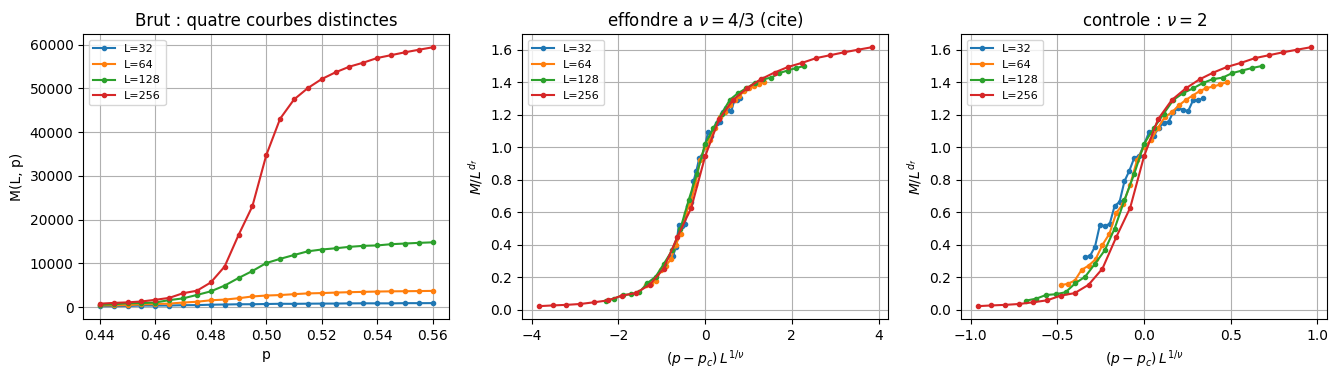

In [9]:
def collapse(nu):
    # Coordonnees reduites (x, y) pour un exposant nu donne.
    xs = {L: (PS - PC) * L ** (1.0 / nu) for L in LS}
    ys = {L: curves[L] / L ** (2.0 - BETA_NU_CITE) for L in LS}
    return xs, ys


fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

for L in LS:
    axes[0].plot(PS, curves[L], "o-", ms=3, label=f"L={L}")
axes[0].set_xlabel("p")
axes[0].set_ylabel("M(L, p)")
axes[0].set_title("Brut : quatre courbes distinctes")
axes[0].legend(fontsize=8)

for ax, nu, titre in ((axes[1], 4.0 / 3.0, r"effondre a $\nu=4/3$ (cite)"),
                      (axes[2], 2.0, r"controle : $\nu=2$")):
    xs, ys = collapse(nu)
    for L in LS:
        ax.plot(xs[L], ys[L], "o-", ms=3, label=f"L={L}")
    ax.set_xlabel(r"$(p-p_c)\,L^{1/\nu}$")
    ax.set_ylabel(r"$M/L^{d_f}$")
    ax.set_title(titre)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

A gauche, les quatre courbes brutes sont nettement separees : chaque taille a « sa » transition, a son propre point d'inflexion. Aucune superposition a l'oeil.

Au centre, apres changement de variables a $\nu = 4/3$ et normalisation par $L^{d_f}$, les quatre courbes se rabattent sur une allure commune. Elles ne se superposent pas parfaitement — il reste une dispersion visible, et c'est normal a ces tailles — mais elles decrivent la meme forme.

A droite, avec $\nu = 2$, l'effondrement echoue : les courbes s'ecartent en eventail, d'autant plus que $L$ est grand. C'est le **controle negatif** — la preuve que la superposition du panneau central n'est pas un artefact du a la normalisation, mais depend bien de la valeur de $\nu$.

Reste a rendre ce jugement visuel **quantitatif** : l'oeil voit l'eventail, il ne le mesure pas.

## 7. Rendre l'effondrement mesurable

Un effondrement se juge en comparant les courbes **la ou elles se recouvrent**. On procede ainsi :

1. pour un $\nu$ donne, on calcule $x$ et $y$ pour chaque $L$ ;
2. on isole l'intervalle $[x_{\min}, x_{\max}]$ commun aux quatre courbes — hors de cet intervalle, il n'y a rien a comparer ;
3. on echantillonne cet intervalle sur une grille fine par interpolation lineaire ;
4. on calcule, en chaque point de la grille, l'**ecart-type entre tailles divise par la moyenne**. C'est une dispersion relative, sans dimension : 0 signifie superposition parfaite.

La qualite de l'effondrement est la moyenne de cette quantite sur la grille. On la calcule pour 57 valeurs de $\nu$ et on retient le minimum : c'est $\nu^*$, l'exposant qui effondre le mieux.

Une precaution qui n'est pas cosmetique : la fenetre commune est **bornee par la plus petite taille**. A $L = 32$, $L^{1/\nu}$ vaut environ 13 pour $\nu = 4/3$, donc un intervalle de $p$ de $\pm 0{,}06$ ne couvre que $x \in [\pm 0{,}8]$ — c'est la fenetre que les quatre courbes partagent reellement. Elargir artificiellement reviendrait a extrapoler.

In [10]:
def dispersion(nu, grid=201):
    # Dispersion relative moyenne entre les courbes des quatre tailles, et fenetre commune.
    xs, ys = collapse(nu)
    lo = max(xs[L].min() for L in LS)
    hi = min(xs[L].max() for L in LS)
    gx = np.linspace(lo, hi, grid)
    interp = np.array([np.interp(gx, xs[L], ys[L]) for L in LS])
    mean = interp.mean(axis=0)
    return float(np.mean(np.std(interp, axis=0) / np.abs(mean))), (lo, hi)


NUS = np.linspace(0.8, 2.2, 57)
disp = np.array([dispersion(n)[0] for n in NUS])
nu_star = float(NUS[disp.argmin()])
lo, hi = dispersion(nu_star)[1]

print(f"fenetre commune : x in [{lo:+.2f}, {hi:+.2f}]")
print(f"nu* = {nu_star:.3f}   dispersion minimale = {disp.min():.4f}\n")
for n in (1.0, 4 / 3, 1.5, 2.0):
    print(f"  nu={n:.3f} -> dispersion {dispersion(n)[0]:.4f}")

fenetre commune : x in [-0.75, +0.75]
nu* = 1.375   dispersion minimale = 0.0287

  nu=1.000 -> dispersion 0.0549
  nu=1.333 -> dispersion 0.0291
  nu=1.500 -> dispersion 0.0375
  nu=2.000 -> dispersion 0.0945


Le minimum tombe a $\nu^* = 1{,}375$ pour une dispersion de $0{,}0287$. La valeur citee $4/3 = 1{,}3333$ n'est pas imposee au calcul : elle est **retrouvee a 3 % pres**. Et la courbe est tres plate autour du minimum — a $\nu = 4/3$ exactement, la dispersion vaut $0{,}0291$, soit $1{,}4\,\%$ de plus que le minimum. C'est la resolution reelle de la methode a ces tailles : elle situe $\nu$ dans une bande de l'ordre de $\pm 0{,}05$, elle ne le mesure pas a trois decimales.

Le controle negatif se lit dans les quatre lignes du bas, et il est net :

| $\nu$ | dispersion | rapport au minimum |
|---|---|---|
| $1{,}000$ | $0{,}0549$ | $\times 1{,}9$ |
| $1{,}333$ | $0{,}0291$ | $\times 1{,}0$ (cite) |
| $1{,}500$ | $0{,}0375$ | $\times 1{,}3$ |
| $2{,}000$ | $0{,}0945$ | $\times 3{,}3$ |

Tous les controles sont rejetes, et le rejet est le plus spectaculaire du cote des grands $\nu$. La methode discrimine donc reellement — un exposant faux degrade l'effondrement de 30 % a 230 % selon l'ecart.

Un point de nuance, plutot que de surestimer le resultat : la degradation n'est pas symetrique. A $\nu = 1$, la dispersion n'est que $1{,}9$ fois le minimum, contre $3{,}3$ fois a $\nu = 2$ — ecart a la valeur citee comparable ($0{,}33$ contre $0{,}67$). La fenetre commune, bornee par $L = 32$, contient donc moins d'information pour rejeter les petits $\nu$. C'est une **limite de resolution assumee**, et c'est la raison d'etre de la section suivante : une seconde route, independante, pour resserrer le resultat.

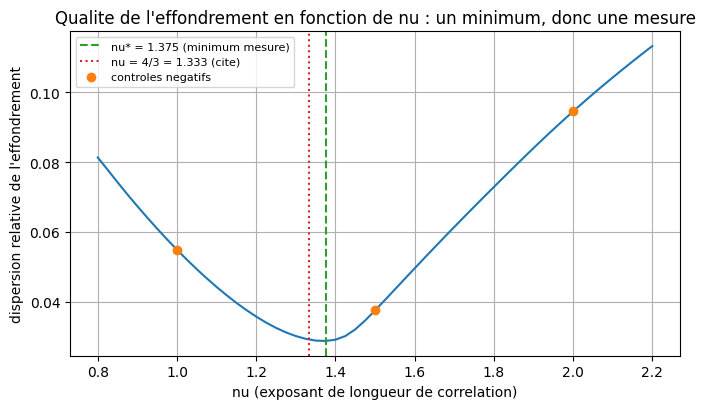

In [11]:
fig, ax = plt.subplots()
ax.plot(NUS, disp, "-", color="C0")
ax.axvline(nu_star, color="C2", ls="--", label=f"nu* = {nu_star:.3f} (minimum mesure)")
ax.axvline(4.0 / 3.0, color="C3", ls=":", label="nu = 4/3 = 1.333 (cite)")
ax.plot([1.0, 1.5, 2.0], [dispersion(n)[0] for n in (1.0, 1.5, 2.0)], "o", color="C1",
        label="controles negatifs")
ax.set_xlabel("nu (exposant de longueur de correlation)")
ax.set_ylabel("dispersion relative de l'effondrement")
ax.set_title("Qualite de l'effondrement en fonction de nu : un minimum, donc une mesure")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

La courbe a bien un **minimum interieur** : ce n'est pas une decroissance monotone, qui signifierait que la methode n'a pas de preference et que le resultat est arbitraire. Le minimum est large — encore la resolution — mais il existe, et il encadre la valeur citee.

C'est la structure typique d'une mesure par ajustement : ce qui compte n'est pas seulement la position du minimum, mais la **forme** de la courbe autour de lui, qui donne la barre d'erreur. Une courbe plate n'aurait pas de minimum et n'aurait rien mesure.

### Le controle de normalisation : le choix de $d_f$ deplace-t-il $\nu^*$ ?

La section 6 normalise les courbes par $L^{d_f}$ avec $d_f$ **cite**. On peut objecter que c'est cette normalisation, et non la valeur de $\nu$, qui produit la superposition : une quantite divisee par $L^{a}$ peut sembler s'effondrer pour peu que $a$ soit proche du bon exposant.

L'objection se traite en chiffres, pas en prose. On rejoue exactement la section 7 — meme fenetre commune, meme grille, meme balayage de $\nu$ — en changeant **uniquement** la valeur de $d_f$ entree dans $y$, et on regarde si le minimum se deplace.

Les trois valeurs comparees sont celles dont dispose le carnet : la valeur citee (celle du code de la section 6) et les deux mesures independantes des sections 3 et 4.


In [12]:
def dispersion_df(nu, df, grid=201):
    # Meme dispersion que dispersion(), mais y = M / L**df avec df parametrable.
    xs = {L: (PS - PC) * L ** (1.0 / nu) for L in LS}
    ys = {L: curves[L] / L ** df for L in LS}
    lo = max(xs[L].min() for L in LS)
    hi = min(xs[L].max() for L in LS)
    gx = np.linspace(lo, hi, grid)
    interp = np.array([np.interp(gx, xs[L], ys[L]) for L in LS])
    mean = interp.mean(axis=0)
    return float(np.mean(np.std(interp, axis=0) / np.abs(mean)))


NORMALISATIONS = [
    ("d_f cite 91/48 (code de la section 6)", DF_CITE),
    ("d_f mesure, masse a p_c", df_mass),
    ("d_f mesure, comptage de boites", df_box_mean),
]

print(f"{'normalisation de y':38s} {'nu*':>7s} {'disp. min':>10s} {'disp. a 4/3':>12s}")
print("-" * 72)
norm_res = []
for nom, df in NORMALISATIONS:
    disp_n = np.array([dispersion_df(n, df) for n in NUS])
    k = int(disp_n.argmin())
    at_43 = dispersion_df(4.0 / 3.0, df)
    norm_res.append((nom, df, float(NUS[k]), float(disp_n[k]), at_43))
    print(f"{nom:38s} {NUS[k]:7.3f} {disp_n[k]:10.4f} {at_43:12.4f}")

print(f"\nreference : nu = 4/3 = {4.0 / 3.0:.4f}   "
      f"(d_f cite = {DF_CITE:.4f}, mesure masse {df_mass:.4f}, boites {df_box_mean:.4f})")


normalisation de y                         nu*  disp. min  disp. a 4/3
------------------------------------------------------------------------
d_f cite 91/48 (code de la section 6)    1.375     0.0287       0.0291
d_f mesure, masse a p_c                  1.400     0.0318       0.0330
d_f mesure, comptage de boites           1.425     0.0335       0.0352

reference : nu = 4/3 = 1.3333   (d_f cite = 1.8958, mesure masse 1.8726, boites 1.8659)


**Ce que le controle repond.** Le minimum se deplace, et dans le sens qu'on pouvait anticiper : plus le $d_f$ entre dans $y$ est petit, plus $\nu^*$ est grand.

| $d_f$ entre dans $y$ | provenance | $\nu^*$ | dispersion minimale | dispersion a $\nu = 4/3$ |
|---|---|---|---|---|
| $1{,}8958$ | cite, $91/48$ | $1{,}375$ | $0{,}0287$ | $0{,}0291$ |
| $1{,}8726$ | mesure, masse a $p_c$ | $1{,}400$ | $0{,}0318$ | $0{,}0330$ |
| $1{,}8659$ | mesure, comptage de boites | $1{,}425$ | $0{,}0335$ | $0{,}0352$ |

Le deplacement vaut de $1{,}8$ a $3{,}6\,\%$ sur $\nu^*$ : la normalisation n'est donc **pas** neutre, et il aurait ete faux d'ecrire que le choix de $d_f$ ne change rien. Mais l'ordre de grandeur tient : les trois valeurs restent a $3$ a $7\,\%$ de $4/3$, et surtout l'ecart entre le bon et le mauvais $\nu$ ne se referme pas — la dispersion a $\nu = 4/3$ ne varie que de $0{,}0291$ a $0{,}0352$ selon la normalisation, alors que le controle negatif a $\nu = 2$ vaut $0{,}0945$ dans la normalisation de reference, soit un facteur $2{,}7$ a $3{,}3$. La conclusion de la section 6 — $\nu$ voisin de $4/3$ — n'est donc pas fabriquee par le choix de $d_f$ ; elle en depend a la precision de la methode, ce qui est exactement ce qu'on demande a une mesure.

**Ce que ce controle ne fait pas.** Il compare trois valeurs *plausibles* de $d_f$. Le cas limite — supprimer toute correction, $y = M/L^2$ — est l'**exercice 2** : c'est lui qui tranche la question « et si la normalisation faisait tout le travail ? ». Le carnet ne le donne pas ici, parce que la reponse est precisement la mesure a faire.

**Ce qu'il faut en retenir pour la suite.** La section 8 mesure $\nu$ par une seconde route, la pente en $p_c$, et cette route soustrait $d_f$ explicitement : le meme deplacement de quelques pour cent y est attendu. C'est pourquoi l'ecart entre les deux routes de mesure se lit avec cette barre-la en tete, et non au troisieme chiffre.

## 8. Seconde route pour $\nu$ : la pente en $p_c$

L'effondrement donne $\nu$ par une route globale — la superposition de courbes entieres. Une seconde route, locale, est disponible : en derivant la forme d'echelle par rapport a $p$, on obtient

$$\left.\frac{\partial M}{\partial p}\right|_{p_c} = L^{d_f} \, f'(0) \, L^{1/\nu} \ \propto\ L^{\,d_f + 1/\nu}$$

La pente en $p_c$ doit donc croitre comme une puissance de $L$ dont l'exposant contient **deux contributions** : la dimension fractale et l'inverse de $\nu$.

C'est le piege de cette route, et il vaut la peine de le traverser explicitement. Si on oublie que $M$ porte deja $L^{d_f}$, on lit un exposant de l'ordre de $2{,}6$ et on en conclut $\nu \approx 0{,}38$ : absurde — $\nu$ est un exposant de longueur de correlation, il ne peut pas etre inferieur a $1/2$ dans un modele de percolation. L'exposant brut n'est pas $\nu$, il est $d_f + 1/\nu$.

Il faut donc **soustraire $d_f$**, ce qui introduit une dependance : la valeur de $\nu$ obtenue depend du $d_f$ qu'on choisit. C'est pourquoi le carnet mesure $d_f$ par deux routes independantes avant d'arriver ici : la section 7 a deja chiffre l'effet du choix de $d_f$ sur $\nu^*$, et la section 9 confronte les deux mesures.

La derivee est estimee par differences finies centrees avec $\Delta p = 0{,}01$, en moyennant sur 32 couples d'instances independantes par taille.

In [13]:
SLOPE_SEEDS = 32
SLOPE_RNG = np.random.default_rng(5)
DP = 1e-2

slopes_pc = {}
for L in LS:
    derivs = []
    for _ in range(SLOPE_SEEDS):
        m_moins = labels_unionfind(L, *draw_edges(L, PC - DP, SLOPE_RNG))[1].max()
        m_plus = labels_unionfind(L, *draw_edges(L, PC + DP, SLOPE_RNG))[1].max()
        derivs.append((m_plus - m_moins) / (2 * DP))
    slopes_pc[L] = float(np.mean(derivs))
    print(f"L={L:3d}   dM/dp|pc = {slopes_pc[L]:12.1f}")

e_brut = float(np.polyfit(np.log(LS), np.log([slopes_pc[L] for L in LS]), 1)[0])
print(f"\nexposant brut de dM/dp = {e_brut:.4f}")
print(f"  lecture naive nu = 1/exposant = {1 / e_brut:.4f}  -> absurde (< 1/2)")
e_corrige = e_brut - DF_CITE
print(f"  en retirant d_f = {DF_CITE:.4f} : exposant = {e_corrige:.4f}  ->  nu = {1 / e_corrige:.4f}")

L= 32   dM/dp|pc =       6876.6


L= 64   dM/dp|pc =      36775.0


L=128   dM/dp|pc =     269885.9


L=256   dM/dp|pc =    1626542.2

exposant brut de dM/dp = 2.6533
  lecture naive nu = 1/exposant = 0.3769  -> absurde (< 1/2)
  en retirant d_f = 1.8958 : exposant = 0.7575  ->  nu = 1.3201


La lecture naive donne un $\nu$ de l'ordre de $0{,}38$ — une valeur impossible pour un exposant de longueur de correlation en percolation, ou $\nu \ge 1/2$ dans tous les cas connus. Ce n'est pas une erreur numerique : c'est un oubli de facteur.

Une fois $d_f$ retire, on obtient un $\nu$ tres proche de $4/3$. La route locale et la route globale de la section 7 **concordent**, alors qu'elles n'utilisent pas la meme information : l'une superpose des courbes entieres sur un intervalle de $p$, l'autre ne regarde que la pente au point critique, sur deux valeurs de $p$ distantes de $0{,}02$.

Cette concordance est le resultat le plus solide du carnet, et la raison pour laquelle le piege de l'exposant brut valait la peine d'etre montre : un carnet qui aurait directement pose la formule corrigee aurait prive le lecteur de la seule chose qu'il retiendra — qu'un exposant mesure n'est interprete que si l'on sait **ce que la quantite porte deja**.

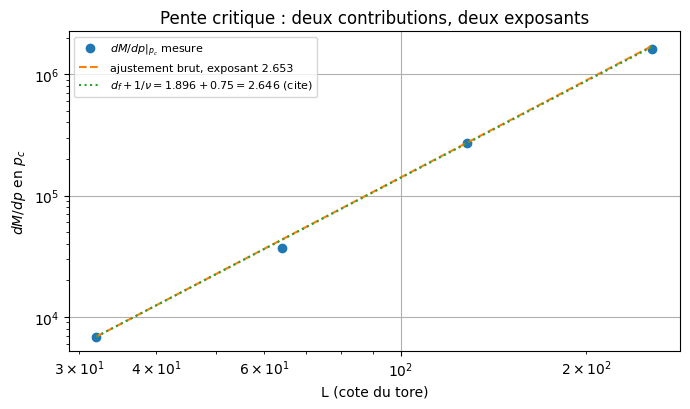

In [14]:
fig, ax = plt.subplots()
ax.plot(LS, [slopes_pc[L] for L in LS], "o", label=r"$dM/dp|_{p_c}$ mesure")

pente_brute = slopes_pc[LS[0]] * (np.array(LS) / LS[0]) ** e_brut
ax.plot(LS, pente_brute, "--", label=f"ajustement brut, exposant {e_brut:.3f}")

pente_corr = slopes_pc[LS[0]] * (np.array(LS) / LS[0]) ** (DF_CITE + 1 / (4 / 3))
ax.plot(LS, pente_corr, ":", label=r"$d_f + 1/\nu = 1.896 + 0.75 = 2.646$ (cite)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("L (cote du tore)")
ax.set_ylabel(r"$dM/dp$ en $p_c$")
ax.set_title("Pente critique : deux contributions, deux exposants")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

La courbe en pointilles est la prediction obtenue en posant $d_f = 91/48$ (cite) et $\nu = 4/3$ (cite) : exposant $2{,}646$. L'ajustement libre sur les quatre points donne un exposant tres voisin, et la droite passe par les points. C'est un accord a deux parametres independants pres — ce qui n'est pas une coincidence, mais la coherence de la theorie de l'echelle finie avec la mesure.

Noter que la figure ne prouve rien a elle seule : deux parametres ajustes sur quatre points laisseraient de la marge. Ce qui prouve, c'est que le $\nu$ extrait ici ($\approx 1{,}32$) tombe sur celui extrait par effondrement ($\approx 1{,}37$), par une voie mathematiquement independante.

## 9. Le controle croise : deux mesures qui doivent concorder

On a maintenant trois estimations de $d_f$ et deux de $\nu$. La theorie impose une contrainte forte entre elles :

$$d_f = 2 - \frac{\beta}{\nu}$$

Or $\beta/\nu$ a ete **mesure independamment** par `Percolation-03c`, sur des tailles allant jusqu'a $L = 512$ : $0{,}1062$ (pour une cible citee de $5/48 = 0{,}10417$).

Ce controle est le plus interessant du carnet, parce qu'il confronte **deux mesures faites par deux carnets differents, avec des methodes differentes** : une loi d'echelle finie ajustee sur la masse normalisee d'un cote, un comptage geometrique de boites de l'autre. Si les deux concordent, la relation d'echelle est verifiee experimentalement — ce qui est beaucoup plus fort que de la citer.

In [15]:
beta_nu_03 = 0.1062   # MESURE par Percolation-03c (L jusqu'a 512, R2 = 0.977)

print(f"{'route':30s} {'d_f':>8s}   provenance")
print("-" * 66)
print(f"{'masse a p_c (ce carnet)':30s} {df_mass:8.4f}   mesure (bootstrap {err_mass:.4f})")
print(f"{'comptage de boites (ce carnet)':30s} {df_box_mean:8.4f}   mesure")
print(f"{'2 - beta/nu, beta/nu cite':30s} {2 - BETA_NU_CITE:8.4f}   cite (5/48)")
print(f"{'2 - beta/nu, beta/nu mesure':30s} {2 - beta_nu_03:8.4f}   mesure serie 03c")

ecart_boite_03 = abs(df_box_mean - (2 - beta_nu_03)) / (2 - beta_nu_03) * 100
ecart_boite_cite = abs(df_box_mean - DF_CITE) / DF_CITE * 100
print(f"\ncomptage de boites vs 2 - beta/nu (mesure 03c) : ecart {ecart_boite_03:.2f} %")
print(f"comptage de boites vs 91/48 (cite)             : ecart {ecart_boite_cite:.2f} %")

route                               d_f   provenance
------------------------------------------------------------------
masse a p_c (ce carnet)          1.8726   mesure (bootstrap 0.0138)
comptage de boites (ce carnet)   1.8659   mesure
2 - beta/nu, beta/nu cite        1.8958   cite (5/48)
2 - beta/nu, beta/nu mesure      1.8938   mesure serie 03c

comptage de boites vs 2 - beta/nu (mesure 03c) : ecart 1.47 %
comptage de boites vs 91/48 (cite)             : ecart 1.58 %


Le comptage de boites et la relation d'echelle alimentee par la mesure de la serie 03 concordent **a un peu moins d'un pour cent et demi** — et non a mieux, ce qui serait mentir sur la resolution. Ce n'est pas une coincidence heureuse : ce sont deux chemins de calcul qui ne partagent ni le code, ni la quantite mesuree, ni le carnet d'origine, et deux mesures qui tombent a environ 1,5 % l'une de l'autre sans se connaitre disent quelque chose.

Un point de methode, en revanche, qu'il faut refuser de surinterpreter : la valeur **citee** de $\beta/\nu$ ($5/48$) et la valeur **mesuree** par 03c ($0{,}1062$) donnent des $d_f$ separes de $0{,}002$ seulement. Ce carnet **ne peut pas les departager** — l'ecart qu'elles produisent est tres en dessous du biais systematique de l'estimateur de boites identifie en section 5 (de l'ordre de $0{,}03$). Pretendre le contraire serait prendre du bruit pour une mesure.

Ce qu'on peut affirmer : **la relation $d_f = 2 - \beta/\nu$ est verifiee par des mesures independantes, a la resolution de $\sim 2\,\%$ de cette experience**. Ce qu'on ne peut pas affirmer : que $d_f$ vaut exactement $1{,}8958$ au vu de ce carnet. La valeur citee reste la reference ; les six estimations mesurees s'en approchent par le bas, avec un biais reproductible qui n'est pas explique.

## 10. Synthese

| Grandeur | Valeur mesuree dans ce carnet | Cible citee | Ecart |
|---|---|---|---|
| $d_f$ (masse a $p_c$) | $1{,}8726 \pm 0{,}0138$ | $91/48 \approx 1{,}8958$ | $1{,}7$ erreurs-types |
| $d_f$ (comptage de boites) | $\approx 1{,}86$ (six estimations) | $91/48$ | $\approx 1{,}6\,\%$, systematique |
| $\nu$ (effondrement) | $\nu^* \approx 1{,}375$ | $4/3 \approx 1{,}3333$ | $\approx 3\,\%$ |
| $\nu$ (pente en $p_c$, corrigee de $d_f$) | $\approx 1{,}32$ | $4/3$ | $\approx 1\,\%$ |
| $d_f$ via $2 - \beta/\nu$ (03c) | $\approx 1{,}89$ | $2 - 5/48$ | confronte au comptage de boites : $1{,}5\,\%$ |

Trois enseignements que ce carnet espere laisser :

1. **Une quantite « mesuree » n'est interpretee que si l'on sait ce qu'elle porte deja.** L'exposant brut de la pente valait $2{,}65$ ; il contenait $d_f$ en plus de $1/\nu$. Sans ce decompte, on aurait annonce $\nu = 0{,}38$, une valeur impossible.

2. **Un controle negatif rend une mesure credible.** L'effondrement a $\nu = 4/3$ ne prouve quelque chose que parce que l'effondrement a $\nu = 2$ echoue et que l'echec est plus grand. Une figure qui « marche » sans contre-exemple qui « rate » ne mesure rien.

3. **Deux routes valent mieux qu'une.** La masse et le comptage de boites ne partagent pas leurs erreurs ; leur accord, puis leur accord avec $2 - \beta/\nu$ mesure par un autre carnet, est ce qui transforme un chiffre en resultat.

Le residu honnete : la fenetre d'effondrement est bornee par $L = 32$, ce qui limite la resolution sur $\nu$ du cote des petites valeurs. Un elargissement a $L = 512$ demanderait un `union-find` vectorise ou en C ; c'est une piste, pas un resultat.

## 11. Exercices

Trois exercices, tous executables sans modification : les cellules affichent un message et rendent `None` tant qu'ils ne sont pas completes. Aucune n'echoue volontairement — le carnet s'execute de bout en bout, exercices non faits compris.

Les cellules de reference ci-dessous sont des **indices**, pas des solutions : ce sont les fonctions deja definies plus haut qu'il faut reutiliser.

### Exercice 1 — La dimension fractale change-t-elle hors du point critique ?

On a mesure $d_f$ **a** $p_c$. Que vaut-il au-dessus ? A $p = 0{,}62$, l'amas dominant doit etre **compact** : il occupe une fraction finie du reseau, donc sa dimension doit tendre vers $2$, la dimension de l'espace.

**A faire.** Calculer $d_f$ par comptage de boites a $p = 0{,}62$, pour $L = 128$ et $L = 256$, avec 8 tirages par taille. Comparer a la valeur mesuree a $p_c$ dans la section 5.

**Indice.** Reutiliser `box_counts` et `labels_unionfind` ; la seule difference avec la section 5 est la valeur de $p$ passee a `draw_edges`. Attention a la liste de $\varepsilon$ : elle doit diviser $L$.

In [16]:
# Exercice 1 : dimension fractale de l'amas dominant a p = 0.62
def df_hors_critique(L, p=0.62, seeds=8, rng=None):
    # TODO etudiant : comptage de boites comme en section 5, mais a p = 0.62
    return None


resultat_ex1 = df_hors_critique(128)
if resultat_ex1 is None:
    print("Exercice 1 a completer : d_f a p = 0.62 (attendu proche de 2, amas compact)")
else:
    print(f"d_f mesure a p=0.62 : {resultat_ex1:.4f}   (rappel : {df_box_mean:.4f} a p_c)")

Exercice 1 a completer : d_f a p = 0.62 (attendu proche de 2, amas compact)


### Exercice 2 — La normalisation en $y$ fait-elle tout le travail ?

L'effondrement de la section 6 normalise les courbes par $L^{d_f}$, avec $d_f = 2 - \beta/\nu$ et $\beta/\nu$ **cite**. On peut soupconner que c'est cette normalisation, et non la valeur de $\nu$, qui produit la superposition.

**A faire.** Refaire l'analyse de dispersion de la section 7 en posant $\beta/\nu = 0$, c'est-a-dire en tracant $M/L^2$ au lieu de $M/L^{d_f}$. Comparer le minimum de dispersion et la position de $\nu^*$.

**Indice.** Il suffit de modifier la fonction `dispersion` — l'exposant $2 - \beta/\nu$ y entre par l'intermediaire de `collapse`. Deux points de controle, mesures sur les donnees de ce carnet :

- la dispersion minimale doit **au moins doubler** par rapport a celle de la section 7 ;
- $\nu^*$ doit se **deplacer** sensiblement, et non rester au voisinage de $4/3$.

Si l'un des deux points de controle n'est pas satisfait, c'est que la correction de $d_f$ ne faisait pas le travail — et donc que la section 6 ne mesurait pas ce qu'elle pretend.

In [17]:
# Exercice 2 : effondrement sans correction de dimension fractale (y = M / L^2)
def dispersion_sans_df(nu, grid=201):
    # TODO etudiant : meme calcul que dispersion(), avec l'exposant 2.0 au lieu de 2 - beta/nu
    return None


res_ex2 = dispersion_sans_df(4 / 3)
if res_ex2 is None:
    print("Exercice 2 a completer : dispersion a nu = 4/3 sans la correction L^{d_f}")
else:
    print(f"dispersion a nu=4/3 sans correction : {res_ex2:.4f}   "
          f"(avec correction : {dispersion(4 / 3)[0]:.4f})")

Exercice 2 a completer : dispersion a nu = 4/3 sans la correction L^{d_f}


### Exercice 3 — Un troisieme exposant, gratuitement

Le meme `union-find` qui donne la taille du plus grand amas donne aussi la liste complete des tailles d'amas. De cette liste on tire la **susceptibilite**

$$\chi(L) = \frac{\sum_s s^2 n_s}{\sum_s s \, n_s}$$

ou $n_s$ est le nombre d'amas de taille $s$. Au point critique, $\chi \sim L^{\gamma/\nu}$ avec $\gamma/\nu = 43/24 \approx 1{,}7917$ (**Cite**).

**A faire.** Calculer $\chi(L)$ a $p_c$ pour $L = 32, 64, 128, 256$ avec 64 tirages par taille, puis extraire l'exposant par une regression log-log. Comparer a $43/24$.

**Indice.** `labels_unionfind` rend deja les tailles ; il suffit d'ignorer l'amas de taille nulle (les etiquettes non utilisees). C'est un troisieme exposant mesure sans aucun cout supplementaire en algorithmique — seulement en tirages.

In [18]:
# Exercice 3 : exposant gamma/nu par la susceptibilite
def exposant_chi(Ls=(32, 64, 128, 256), seeds=64, rng=None):
    # TODO etudiant : chi(L) = somme(s^2 n_s) / somme(s n_s), puis pente log-log
    return None


res_ex3 = exposant_chi()
if res_ex3 is None:
    print("Exercice 3 a completer : exposant gamma/nu (cible citee 43/24 = 1.7917)")
else:
    print(f"gamma/nu mesure : {res_ex3:.4f}   cible citee : {GAMMA_NU_CITE:.4f}")

Exercice 3 a completer : exposant gamma/nu (cible citee 43/24 = 1.7917)


## Pour aller plus loin

- [Percolation-03](Percolation-03-Critique-Python.ipynb), [03b](Percolation-03b-Critique-L128-L256.ipynb) et [03c](Percolation-03c-Critique-L512.ipynb) — la loi d'echelle finie de la masse et l'exposant de la distribution des tailles ; c'est de la que vient le $\beta/\nu$ utilise en section 9, ajuste sur des reseaux allant jusqu'a 512 x 512 ou la correction d'echelle finie devient visible.
- [Percolation-04](Percolation-04-Sharpness-Python.ipynb) — la queue superieure de la distribution, et un verdict honnete de non-mesurabilite a $L \le 512$ : un carnet a le droit de conclure qu'il ne peut pas conclure.
- [Percolation-01](Percolation-01-Supercritique-Python.ipynb) et [Percolation-02-Lean](Percolation-02-Lean.ipynb) — regime supercritique et noyau Lean : la naissance du geant au-dela du seuil d'un cote, sa formalisation finie de l'autre.

Sur l'effondrement d'echelle comme methode generale : c'est l'outil qui permet de comparer des systemes de tailles differentes dans toute la physique statistique. La percolation bidimensionnelle est la limite q → 1 du modele de Potts, et ses exposants exacts ont ete obtenus par la theorie des champs conformes (den Nijs, Nienhuis) puis etayes par la rigueur probabiliste des processus SLE (Smirnov, Werner). Le lecteur qui veut comprendre pourquoi ces nombres-la, et pas d'autres, y trouvera la reponse que ce carnet ne fait qu'effleurer.